In [1]:
# BLOCK 1: IMPORTS & SETUP

import os
import copy
import math
import random
import time
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, ConcatDataset, Subset
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully.")

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
else:
    print("CUDA not available. Running on CPU.")

# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # For reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Seed set to: {seed}")

set_seed(42)

All libraries imported successfully.
Using device: cuda
GPU Name: Tesla T4
CUDA Version: 12.8
Seed set to: 42


In [2]:
# BLOCK 2: PATHS, TRANSFORMS, TASK SETUP

!pip install -q kaggle

import os

os.environ['KAGGLE_USERNAME'] = "aruna4"
os.environ['KAGGLE_KEY'] = "fabb0946078c052efc978557cfd54477"

!kaggle datasets download -d nodoubttome/skin-cancer9-classesisic
!unzip -q skin-cancer9-classesisic.zip -d skin_cancer_data

base_path = "skin_cancer_data/Skin cancer ISIC The International Skin Imaging Collaboration"

TRAIN_PATH = os.path.join(base_path, "Train")
TEST_PATH  = os.path.join(base_path, "Test")

print("Train Path:", TRAIN_PATH)
print("Test Path :", TEST_PATH)

print("\nChecking dataset folders...")
print("Train folder exists:", os.path.exists(TRAIN_PATH))
print("Test folder exists :", os.path.exists(TEST_PATH))

# Image settings
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

# Transforms
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225])
])

print("\nTransforms created successfully.")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")

# Load once here only to get class names for task split
temp_dataset = datasets.ImageFolder(TRAIN_PATH)

num_total_classes = len(temp_dataset.classes)
print("\nTotal Classes:", num_total_classes)

class_names = sorted(temp_dataset.classes)

# Keep DER++ variable names unchanged
CLASS_ORDER = class_names

TASKS = [
    class_names[0:3],
    class_names[3:6],
    class_names[6:9]
]

print("\nClass Order:")
for i, cls in enumerate(CLASS_ORDER):
    print(f"{i}: {cls}")

print("\nIncremental Tasks:")
for step, task in enumerate(TASKS, 1):
    print(f"Step {step}: {task}")

Dataset URL: https://www.kaggle.com/datasets/nodoubttome/skin-cancer9-classesisic
License(s): other
100% 786M/786M [00:04<00:00, 170MB/s] 

Train Path: skin_cancer_data/Skin cancer ISIC The International Skin Imaging Collaboration/Train
Test Path : skin_cancer_data/Skin cancer ISIC The International Skin Imaging Collaboration/Test

Checking dataset folders...
Train folder exists: True
Test folder exists : True

Transforms created successfully.
Image size: 224x224
Batch size: 32

Total Classes: 9

Class Order:
0: actinic keratosis
1: basal cell carcinoma
2: dermatofibroma
3: melanoma
4: nevus
5: pigmented benign keratosis
6: seborrheic keratosis
7: squamous cell carcinoma
8: vascular lesion

Incremental Tasks:
Step 1: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Step 2: ['melanoma', 'nevus', 'pigmented benign keratosis']
Step 3: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']


In [3]:
# BLOCK 3: LOAD FULL DATASETS AND VERIFY MAP

# Load with ImageFolder
full_train_dataset = datasets.ImageFolder(TRAIN_PATH, transform=train_transform)
full_test_dataset  = datasets.ImageFolder(TEST_PATH, transform=test_transform)

print("Datasets loaded successfully.")

print("\nImageFolder detected classes:")
print("Train classes:", full_train_dataset.classes)
print("Test classes :", full_test_dataset.classes)

# Original mapping from folder names
train_class_to_idx = full_train_dataset.class_to_idx
test_class_to_idx = full_test_dataset.class_to_idx

print("\nTrain class_to_idx:")
for k, v in train_class_to_idx.items():
    print(f"{k} -> {v}")

print("\nTest class_to_idx:")
for k, v in test_class_to_idx.items():
    print(f"{k} -> {v}")

# Verify all classes exist
missing_train = [cls for cls in CLASS_ORDER if cls not in train_class_to_idx]
missing_test  = [cls for cls in CLASS_ORDER if cls not in test_class_to_idx]

if len(missing_train) > 0:
    print("\nERROR: Missing classes in TRAIN folder:", missing_train)
else:
    print("\nAll required classes found in TRAIN folder.")

if len(missing_test) > 0:
    print("ERROR: Missing classes in TEST folder:", missing_test)
else:
    print("All required classes found in TEST folder.")

# New fixed class mapping for our experiment
class_to_new_idx = {cls: i for i, cls in enumerate(CLASS_ORDER)}
new_idx_to_class = {i: cls for cls, i in class_to_new_idx.items()}

print("\nNew class mapping for CIL experiment:")
for cls, idx in class_to_new_idx.items():
    print(f"{cls} -> {idx}")

NUM_CLASSES = len(CLASS_ORDER)
print(f"\nTotal number of classes: {NUM_CLASSES}")

Datasets loaded successfully.

ImageFolder detected classes:
Train classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Test classes : ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

Train class_to_idx:
actinic keratosis -> 0
basal cell carcinoma -> 1
dermatofibroma -> 2
melanoma -> 3
nevus -> 4
pigmented benign keratosis -> 5
seborrheic keratosis -> 6
squamous cell carcinoma -> 7
vascular lesion -> 8

Test class_to_idx:
actinic keratosis -> 0
basal cell carcinoma -> 1
dermatofibroma -> 2
melanoma -> 3
nevus -> 4
pigmented benign keratosis -> 5
seborrheic keratosis -> 6
squamous cell carcinoma -> 7
vascular lesion -> 8

All required classes found in TRAIN folder.
All required classes found in TEST folder.

New c

In [4]:
# BLOCK 4: TASK-WISE DATASET WRAPPER & SUBSETS

class RemappedSubset(Dataset):
    def __init__(self, base_dataset, indices, original_class_to_idx, new_class_to_idx):
        self.base_dataset = base_dataset
        self.indices = indices
        self.original_class_to_idx = original_class_to_idx
        self.new_class_to_idx = new_class_to_idx

        # reverse map: original idx -> class name
        self.original_idx_to_class = {v: k for k, v in original_class_to_idx.items()}

        print(f"Created RemappedSubset with {len(self.indices)} samples.")

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, old_label = self.base_dataset[self.indices[idx]]
        class_name = self.original_idx_to_class[old_label]
        new_label = self.new_class_to_idx[class_name]
        return image, new_label


def get_indices_for_classes(imagefolder_dataset, class_names):
    """
    Returns indices of samples belonging to class_names
    """
    class_to_idx = imagefolder_dataset.class_to_idx
    target_class_ids = [class_to_idx[cls] for cls in class_names]

    selected_indices = []
    for i, (_, label) in enumerate(imagefolder_dataset.samples):
        if label in target_class_ids:
            selected_indices.append(i)

    print(f"Found {len(selected_indices)} samples for classes: {class_names}")
    return selected_indices


# Create task-wise train and test datasets
train_task_datasets = []
test_task_datasets = []

for step_id, task_classes in enumerate(TASKS, start=1):
    print(f"\nCreating datasets for Step {step_id}: {task_classes}")

    train_indices = get_indices_for_classes(full_train_dataset, task_classes)
    test_indices  = get_indices_for_classes(full_test_dataset, task_classes)

    train_subset = RemappedSubset(
        base_dataset=full_train_dataset,
        indices=train_indices,
        original_class_to_idx=full_train_dataset.class_to_idx,
        new_class_to_idx=class_to_new_idx
    )

    test_subset = RemappedSubset(
        base_dataset=full_test_dataset,
        indices=test_indices,
        original_class_to_idx=full_test_dataset.class_to_idx,
        new_class_to_idx=class_to_new_idx
    )

    train_task_datasets.append(train_subset)
    test_task_datasets.append(test_subset)

print("\nAll task-wise datasets created successfully.")

for i in range(len(TASKS)):
    print(f"Step {i+1} -> Train samples: {len(train_task_datasets[i])}, Test samples: {len(test_task_datasets[i])}")


Creating datasets for Step 1: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Found 585 samples for classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Found 48 samples for classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Created RemappedSubset with 585 samples.
Created RemappedSubset with 48 samples.

Creating datasets for Step 2: ['melanoma', 'nevus', 'pigmented benign keratosis']
Found 1257 samples for classes: ['melanoma', 'nevus', 'pigmented benign keratosis']
Found 48 samples for classes: ['melanoma', 'nevus', 'pigmented benign keratosis']
Created RemappedSubset with 1257 samples.
Created RemappedSubset with 48 samples.

Creating datasets for Step 3: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Found 397 samples for classes: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
Found 22 samples for classes: ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

In [5]:
# BLOCK 5: DER++ REPLAY BUFFER

class DERPPBuffer:
    def __init__(self, max_size=600):
        self.max_size = max_size
        self.images = []         # stores image tensors (CPU)
        self.labels = []         # stores int labels
        self.logits = []         # stores saved logits (CPU tensor)

        print(f"DER++ Buffer initialized with max size = {self.max_size}")

    def __len__(self):
        return len(self.images)

    def is_empty(self):
        return len(self.images) == 0

    def class_counts(self):
        count_dict = defaultdict(int)
        for lbl in self.labels:
            count_dict[int(lbl)] += 1
        return dict(count_dict)

    def print_summary(self):
        print("\n===== BUFFER SUMMARY =====")
        print(f"Current buffer size: {len(self.images)} / {self.max_size}")
        print("Class distribution:", self.class_counts())

    def add_samples_balanced(self, dataset, model, samples_per_class, batch_size=32):
        """
        Add samples class-balanced from a dataset.
        Stores image, label, and logits.
        """
        print("\nAdding samples to DER++ buffer...")
        print(f"Requested samples per class: {samples_per_class}")

        model.eval()

        # collect indices per class
        indices_per_class = defaultdict(list)
        for idx in range(len(dataset)):
            _, label = dataset[idx]
            indices_per_class[int(label)].append(idx)

        chosen_indices = []
        for cls, idxs in indices_per_class.items():
            random.shuffle(idxs)
            chosen = idxs[:samples_per_class]
            chosen_indices.extend(chosen)
            print(f"Class {cls}: selected {len(chosen)} samples")

        print(f"Total selected samples before logit extraction: {len(chosen_indices)}")

        # create temporary loader
        subset = Subset(dataset, chosen_indices)
        loader = DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

        added = 0
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                outputs = model(images)

                for i in range(images.size(0)):
                    self.images.append(images[i].cpu().clone())
                    self.labels.append(int(labels[i].item()))
                    self.logits.append(outputs[i].cpu().clone())
                    added += 1

        print(f"Added {added} samples to buffer.")

        # if overflow, trim evenly
        if len(self.images) > self.max_size:
            print("Buffer overflow detected. Rebalancing buffer...")
            self.reduce_to_max_size_balanced()

        self.print_summary()

    def reduce_to_max_size_balanced(self):
        """
        Keep buffer balanced across classes.
        """
        print("\nReducing buffer to max size with balanced strategy...")

        indices_per_class = defaultdict(list)
        for i, lbl in enumerate(self.labels):
            indices_per_class[int(lbl)].append(i)

        seen_classes = sorted(indices_per_class.keys())
        num_classes_seen = len(seen_classes)

        if num_classes_seen == 0:
            print("Buffer is empty. Nothing to reduce.")
            return

        keep_per_class = self.max_size // num_classes_seen
        remainder = self.max_size % num_classes_seen

        print(f"Seen classes in buffer: {seen_classes}")
        print(f"Keep per class: {keep_per_class}, remainder: {remainder}")

        kept_indices = []
        for i, cls in enumerate(seen_classes):
            cls_indices = indices_per_class[cls]
            random.shuffle(cls_indices)

            extra = 1 if i < remainder else 0
            num_to_keep = min(len(cls_indices), keep_per_class + extra)
            kept_indices.extend(cls_indices[:num_to_keep])

            print(f"Class {cls}: keeping {num_to_keep} samples")

        kept_indices = sorted(kept_indices)

        self.images = [self.images[i] for i in kept_indices]
        self.labels = [self.labels[i] for i in kept_indices]
        self.logits = [self.logits[i] for i in kept_indices]

        print("Buffer rebalanced successfully.")
        self.print_summary()

    def get_replay_batch(self, batch_size=32):
        """
        Sample replay batch from buffer.
        Returns images, labels, stored_logits
        """
        if self.is_empty():
            return None, None, None

        actual_batch = min(batch_size, len(self.images))
        sampled_indices = random.sample(range(len(self.images)), actual_batch)

        replay_images = torch.stack([self.images[i] for i in sampled_indices]).to(device)
        replay_labels = torch.tensor([self.labels[i] for i in sampled_indices], dtype=torch.long).to(device)
        replay_logits = torch.stack([self.logits[i] for i in sampled_indices]).to(device)

        return replay_images, replay_labels, replay_logits

In [6]:
# BLOCK 6: MODEL SETUP

def build_model(num_classes=6):
    print("\nBuilding ConvNeXt-Tiny model...")

    model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Linear(in_features, num_classes)

    model = model.to(device)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print("Model created successfully.")
    print(f"Final classifier in_features: {in_features}")
    print(f"Number of output classes: {num_classes}")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

    return model


model = build_model(num_classes=NUM_CLASSES)


Building ConvNeXt-Tiny model...
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 161MB/s] 


Model created successfully.
Final classifier in_features: 768
Number of output classes: 9
Total parameters: 27,827,049
Trainable parameters: 27,827,049


In [7]:
# BLOCK 7: DATALOADER HELPERS

def create_loader(dataset, batch_size=BATCH_SIZE, shuffle=True):
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )
    return loader


def get_seen_test_dataset_upto_step(test_task_datasets, step_idx):
    """
    step_idx is 0-based
    returns concatenated test dataset from step 0 to step_idx
    """
    seen_datasets = test_task_datasets[:step_idx + 1]
    combined_dataset = ConcatDataset(seen_datasets)

    print(f"\nCreated seen-test dataset up to step {step_idx + 1}")
    print(f"Number of task test sets combined: {len(seen_datasets)}")
    print(f"Total seen test samples: {len(combined_dataset)}")

    return combined_dataset


# Quick sanity loaders
for i in range(len(train_task_datasets)):
    train_loader_i = create_loader(train_task_datasets[i], shuffle=True)
    test_seen_i = get_seen_test_dataset_upto_step(test_task_datasets, i)
    test_loader_i = create_loader(test_seen_i, shuffle=False)

    print(f"Step {i+1}: Train batches = {len(train_loader_i)}, Seen-test batches = {len(test_loader_i)}")


Created seen-test dataset up to step 1
Number of task test sets combined: 1
Total seen test samples: 48
Step 1: Train batches = 19, Seen-test batches = 2

Created seen-test dataset up to step 2
Number of task test sets combined: 2
Total seen test samples: 96
Step 2: Train batches = 40, Seen-test batches = 3

Created seen-test dataset up to step 3
Number of task test sets combined: 3
Total seen test samples: 118
Step 3: Train batches = 13, Seen-test batches = 4


In [8]:
# BLOCK 8: EVALUATION FUNCTIONS

def evaluate_model(model, dataloader, class_names=None):
    model.eval()

    all_preds = []
    all_labels = []
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    print("\nEvaluating model...")

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            preds = torch.argmax(outputs, dim=1)

            total_loss += loss.item()
            all_preds.extend(preds.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())

    avg_loss = total_loss / len(dataloader)

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    rec = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    cm = confusion_matrix(all_labels, all_preds)

    print("Evaluation completed.")
    print(f"Loss     : {avg_loss:.4f}")
    print(f"Accuracy : {acc*100:.2f}%")
    print(f"Precision: {prec*100:.2f}%")
    print(f"Recall   : {rec*100:.2f}%")
    print(f"F1-score : {f1*100:.2f}%")

    if class_names is not None:
        print("\nClassification Report:")
        print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    return {
        "loss": avg_loss,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "confusion_matrix": cm,
        "all_labels": all_labels,
        "all_preds": all_preds
    }


def plot_confusion_matrix(cm, class_names, title="Confusion Matrix"):
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.title(title)
    plt.colorbar()

    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45, ha='right')
    plt.yticks(tick_marks, class_names)

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()


def get_seen_class_names_upto_step(tasks, step_idx, class_to_new_idx):
    seen_classes = []
    for i in range(step_idx + 1):
        seen_classes.extend(tasks[i])

    seen_classes = sorted(seen_classes, key=lambda x: class_to_new_idx[x])
    return seen_classes


print("\nEvaluation utilities ready.")


Evaluation utilities ready.


In [9]:
# BLOCK 9: EVALUATE ON A SINGLE TASK (TASK-WISE ACCURACY)

def evaluate_on_task(model, dataloader, task_class_names, class_to_new_idx):
    """
    Evaluate model on one specific task dataset only.
    Returns:
        - overall task accuracy
        - per-class accuracy dictionary using actual class names
    """
    model.eval()

    all_preds = []
    all_labels = []

    print("\nEvaluating on one task...")

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy().tolist())
            all_labels.extend(labels.cpu().numpy().tolist())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    task_accuracy = accuracy_score(all_labels, all_preds)

    per_class_acc = {}
    for class_name in task_class_names:
        class_idx = class_to_new_idx[class_name]

        class_mask = (all_labels == class_idx)
        total_class_samples = class_mask.sum()

        if total_class_samples == 0:
            class_acc = 0.0
        else:
            correct = (all_preds[class_mask] == all_labels[class_mask]).sum()
            class_acc = correct / total_class_samples

        per_class_acc[class_name] = class_acc

    print("Single-task evaluation completed.")
    print(f"Task Accuracy: {task_accuracy * 100:.2f}%")

    for cls_name, cls_acc in per_class_acc.items():
        print(f"{cls_name} Accuracy: {cls_acc * 100:.2f}%")

    return task_accuracy, per_class_acc

In [10]:
# BLOCK 10: FUNCTION TO COMPUTE CIL METRICS

def compute_cil_metrics(acc_matrix, current_step_idx):
    """
    Computes CIL metrics up to the current incremental step.

    acc_matrix shape: [num_tasks, num_tasks]
    acc_matrix[i][j] means:
        accuracy on Task j after training Task i

    current_step_idx: 0-based current step

    Returns dictionary with:
        - average_accuracy
        - average_incremental_accuracy
        - forgetting_rate
        - backward_transfer
        - forward_transfer
    """

    # 1. Average Accuracy at step t

    current_task_accuracies = []
    for task_j in range(current_step_idx + 1):
        val = acc_matrix[current_step_idx][task_j]
        if val is not None:
            current_task_accuracies.append(val)

    average_accuracy = np.mean(current_task_accuracies) if len(current_task_accuracies) > 0 else 0.0

    # 2. Average Incremental Accuracy (AIA)

    step_averages = []
    for step_i in range(current_step_idx + 1):
        vals = []
        for task_j in range(step_i + 1):
            if acc_matrix[step_i][task_j] is not None:
                vals.append(acc_matrix[step_i][task_j])

        if len(vals) > 0:
            step_averages.append(np.mean(vals))

    average_incremental_accuracy = np.mean(step_averages) if len(step_averages) > 0 else 0.0

    # 3. Forgetting Rate

    forgetting_list = []
    for task_j in range(current_step_idx):  # only past tasks
        previous_scores = []
        for step_i in range(task_j, current_step_idx):
            if acc_matrix[step_i][task_j] is not None:
                previous_scores.append(acc_matrix[step_i][task_j])

        current_score = acc_matrix[current_step_idx][task_j]

        if len(previous_scores) > 0 and current_score is not None:
            best_past = max(previous_scores)
            forgetting = best_past - current_score
            forgetting_list.append(forgetting)

    forgetting_rate = np.mean(forgetting_list) if len(forgetting_list) > 0 else 0.0

    # 4. Backward Transfer (BWT)

    # BWT = average over old tasks of [A_t,j - A_j,j]
    bwt_list = []
    for task_j in range(current_step_idx):
        final_score = acc_matrix[current_step_idx][task_j]
        initial_score = acc_matrix[task_j][task_j]

        if final_score is not None and initial_score is not None:
            bwt_list.append(final_score - initial_score)

    backward_transfer = np.mean(bwt_list) if len(bwt_list) > 0 else 0.0

    # 5. Forward Transfer (FWT)

    # FWT is tricky without a random baseline.
    # Here we compute a practical version:
    # accuracy on unseen task before learning it, averaged over tasks.
    #
    # acc_matrix[i][j] where i < j means performance on future task j
    # before learning it.
    fwt_list = []
    for future_task in range(1, current_step_idx + 1):
        pre_learning_step = future_task - 1
        val = acc_matrix[pre_learning_step][future_task]

        if val is not None:
            fwt_list.append(val)

    forward_transfer = np.mean(fwt_list) if len(fwt_list) > 0 else 0.0

    return {
        "average_accuracy": average_accuracy,
        "average_incremental_accuracy": average_incremental_accuracy,
        "forgetting_rate": forgetting_rate,
        "backward_transfer": backward_transfer,
        "forward_transfer": forward_transfer
    }

In [11]:
# BLOCK 11: PRINT TASK SUMMARY AFTER EACH STEP

def print_incremental_step_summary(step_idx, task_results_dict, cil_metrics):
    """
    step_idx: 0-based
    task_results_dict example:
    {
        0: {
            "task_name": "Task 1",
            "task_classes": ["Nevus", "Benign keratosis"],
            "task_accuracy": 0.91,
            "per_class_accuracy": {
                "Nevus": 0.92,
                "Benign keratosis": 0.90
            }
        },
        ...
    }
    """

    print("\n" + "=" * 60)
    print(f"SUMMARY AFTER TRAINING TASK {step_idx + 1}")
    print("=" * 60)

    for task_id in range(step_idx + 1):
        result = task_results_dict[task_id]

        print(f"\nTask {task_id + 1}:")
        print(f"Classes: {', '.join(result['task_classes'])}")
        print(f"Task {task_id + 1} Accuracy: {result['task_accuracy'] * 100:.2f}%")

        for class_name, class_acc in result["per_class_accuracy"].items():
            print(f"{class_name} Accuracy: {class_acc * 100:.2f}%")

    print("\n----- CIL Metrics -----")
    print(f"Average Accuracy             : {cil_metrics['average_accuracy'] * 100:.2f}%")
    print(f"Average Incremental Accuracy : {cil_metrics['average_incremental_accuracy'] * 100:.2f}%")
    print(f"Forgetting Rate              : {cil_metrics['forgetting_rate'] * 100:.2f}%")
    print(f"Backward Transfer            : {cil_metrics['backward_transfer'] * 100:.2f}%")
    print(f"Forward Transfer             : {cil_metrics['forward_transfer'] * 100:.2f}%")
    print("=" * 60)

In [12]:
# BLOCK 12: CIL TRACKING STRUCTURES

NUM_TASKS = len(TASKS)

# acc_matrix[i][j] = accuracy on task j after learning task i
acc_matrix = [[None for _ in range(NUM_TASKS)] for _ in range(NUM_TASKS)]

# to store detailed task-wise results after each step
incremental_results = {}

print("Initialized CIL tracking structures.")
print(f"Number of tasks: {NUM_TASKS}")
print("Accuracy matrix shape:", f"{NUM_TASKS} x {NUM_TASKS}")

print("\nInitial Accuracy Matrix:")
for row in acc_matrix:
    print(row)

Initialized CIL tracking structures.
Number of tasks: 3
Accuracy matrix shape: 3 x 3

Initial Accuracy Matrix:
[None, None, None]
[None, None, None]
[None, None, None]


In [13]:
# BLOCK 13: TRAIN ONE TASK USING DER++

def train_one_task_derpp(
    model,
    train_dataset,
    buffer,
    task_id,
    epochs=20,
    lr=1e-4,
    weight_decay=1e-4,
    alpha=0.3,
    beta=0.7,
    replay_batch_size=32
):
    print("\n" + "=" * 70)
    print(f"START TRAINING TASK {task_id + 1}")
    print("=" * 70)

    train_loader = create_loader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    ce_loss = nn.CrossEntropyLoss()
    mse_loss = nn.MSELoss()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_epoch_loss = float("inf")

    history = {"epoch_loss": []}

    for epoch in range(epochs):
        model.train()
        running_total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss_current = ce_loss(outputs, labels)
            total_loss = loss_current

            replay_images, replay_labels, replay_stored_logits = buffer.get_replay_batch(replay_batch_size)

            if replay_images is not None:
                replay_outputs = model(replay_images)
                loss_replay_mse = mse_loss(replay_outputs, replay_stored_logits)
                loss_replay_ce = ce_loss(replay_outputs, replay_labels)
                total_loss = total_loss + alpha * loss_replay_mse + beta * loss_replay_ce

            total_loss.backward()
            optimizer.step()

            running_total_loss += total_loss.item()

        epoch_total_loss = running_total_loss / len(train_loader)
        scheduler.step()
        history["epoch_loss"].append(epoch_total_loss)

        print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_total_loss:.4f}")

        if epoch_total_loss < best_epoch_loss:
            best_epoch_loss = epoch_total_loss
            best_model_wts = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_model_wts)

    print(f"\nBest model restored for Task {task_id + 1}")
    print(f"Best epoch loss: {best_epoch_loss:.4f}")
    print("=" * 70)

    return model, history

In [14]:
# BLOCK 14: UPDATE BUFFER AFTER EACH TASK

def update_buffer_after_task(buffer, model, train_task_datasets, current_task_idx):
    """
    Rebuild the buffer using all seen task datasets up to current task,
    then rebalance class-wise within max_size.
    """

    print("\n" + "=" * 70)
    print(f"UPDATING BUFFER AFTER TASK {current_task_idx + 1}")
    print("=" * 70)

    # Combine all seen datasets
    seen_datasets = train_task_datasets[:current_task_idx + 1]
    combined_seen_dataset = ConcatDataset(seen_datasets)

    print(f"Number of seen task datasets: {len(seen_datasets)}")
    print(f"Combined seen dataset size: {len(combined_seen_dataset)}")

    # Clear current buffer fully, then refill
    buffer.images = []
    buffer.labels = []
    buffer.logits = []

    seen_classes = []
    for i in range(current_task_idx + 1):
        seen_classes.extend(TASKS[i])

    num_seen_classes = len(seen_classes)
    samples_per_class = buffer.max_size // num_seen_classes

    print(f"Seen classes: {seen_classes}")
    print(f"Number of seen classes: {num_seen_classes}")
    print(f"Samples per class to store: {samples_per_class}")

    buffer.add_samples_balanced(
        dataset=combined_seen_dataset,
        model=model,
        samples_per_class=samples_per_class,
        batch_size=BATCH_SIZE
    )

    print(f"Buffer update finished after Task {current_task_idx + 1}")
    print("=" * 70)

In [15]:
# BLOCK 15: EVALUATE ALL TASKS FOR CURRENT STEP

def evaluate_step_and_update_metrics(
    model,
    current_step_idx,
    test_task_datasets,
    acc_matrix,
    incremental_results,
    tasks,
    class_to_new_idx
):
    """
    After finishing training a task:
    1. Evaluate on all seen tasks
    2. Evaluate on future tasks for FWT storage
    3. Compute CIL metrics
    4. Print summary
    """

    print("\n" + "=" * 70)
    print(f"EVALUATION AFTER TASK {current_step_idx + 1}")
    print("=" * 70)

    task_results_dict = {}

    # A. Evaluate on seen tasks

    for task_j in range(current_step_idx + 1):
        print(f"\nEvaluating SEEN Task {task_j + 1} ...")

        task_loader = create_loader(test_task_datasets[task_j], batch_size=BATCH_SIZE, shuffle=False)

        task_acc, per_class_acc = evaluate_on_task(
            model=model,
            dataloader=task_loader,
            task_class_names=tasks[task_j],
            class_to_new_idx=class_to_new_idx
        )

        acc_matrix[current_step_idx][task_j] = task_acc

        task_results_dict[task_j] = {
            "task_name": f"Task {task_j + 1}",
            "task_classes": tasks[task_j],
            "task_accuracy": task_acc,
            "per_class_accuracy": per_class_acc
        }

    # B. Evaluate on future tasks for Forward Transfer

    for future_task in range(current_step_idx + 1, len(tasks)):
        print(f"\nEvaluating FUTURE Task {future_task + 1} for Forward Transfer ...")

        future_loader = create_loader(test_task_datasets[future_task], batch_size=BATCH_SIZE, shuffle=False)

        future_acc, _ = evaluate_on_task(
            model=model,
            dataloader=future_loader,
            task_class_names=tasks[future_task],
            class_to_new_idx=class_to_new_idx
        )

        acc_matrix[current_step_idx][future_task] = future_acc
        print(f"Stored pre-learning accuracy for Task {future_task + 1}: {future_acc * 100:.2f}%")

    # C. Compute CIL metrics

    cil_metrics = compute_cil_metrics(acc_matrix, current_step_idx)

    incremental_results[current_step_idx] = {
        "task_results": task_results_dict,
        "cil_metrics": cil_metrics
    }

    # D. Print summary

    print_incremental_step_summary(
        step_idx=current_step_idx,
        task_results_dict=task_results_dict,
        cil_metrics=cil_metrics
    )

    print("\nUpdated Accuracy Matrix:")
    for row in acc_matrix:
        print(row)

    return acc_matrix, incremental_results

In [16]:
# BLOCK 16: FULL INCREMENTAL TRAINING LOOP

# Hyperparameters
EPOCHS_PER_TASK = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
ALPHA = 0.3
BETA = 0.7
BUFFER_SIZE = 600
REPLAY_BATCH_SIZE = 32

print("\nTraining Configuration")
print(f"EPOCHS_PER_TASK   : {EPOCHS_PER_TASK}")
print(f"LEARNING_RATE     : {LEARNING_RATE}")
print(f"WEIGHT_DECAY      : {WEIGHT_DECAY}")
print(f"ALPHA             : {ALPHA}")
print(f"BETA              : {BETA}")
print(f"BUFFER_SIZE       : {BUFFER_SIZE}")
print(f"REPLAY_BATCH_SIZE : {REPLAY_BATCH_SIZE}")

# Fresh model + fresh buffer
model = build_model(num_classes=NUM_CLASSES)
buffer = DERPPBuffer(max_size=BUFFER_SIZE)

all_task_histories = {}

print("\n" + "=" * 80)
print("STARTING FULL DER++ CLASS-INCREMENTAL TRAINING")
print("=" * 80)

for task_id in range(NUM_TASKS):
    print("\n" + "=" * 80)
    print(f"PROCESSING TASK {task_id + 1}/{NUM_TASKS}")
    print(f"Task classes: {TASKS[task_id]}")
    print("=" * 80)

    # 1. Train on current task

    model, history = train_one_task_derpp(
        model=model,
        train_dataset=train_task_datasets[task_id],
        buffer=buffer,
        task_id=task_id,
        epochs=EPOCHS_PER_TASK,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        alpha=ALPHA,
        beta=BETA,
        replay_batch_size=REPLAY_BATCH_SIZE
    )

    all_task_histories[task_id] = history

    # 2. Update replay buffer

    update_buffer_after_task(
        buffer=buffer,
        model=model,
        train_task_datasets=train_task_datasets,
        current_task_idx=task_id
    )

    # 3. Evaluate + compute CIL metrics

    acc_matrix, incremental_results = evaluate_step_and_update_metrics(
        model=model,
        current_step_idx=task_id,
        test_task_datasets=test_task_datasets,
        acc_matrix=acc_matrix,
        incremental_results=incremental_results,
        tasks=TASKS,
        class_to_new_idx=class_to_new_idx
    )

print("\n" + "=" * 80)
print("FULL DER++ TRAINING COMPLETED")
print("=" * 80)


Training Configuration
EPOCHS_PER_TASK   : 20
LEARNING_RATE     : 0.0001
WEIGHT_DECAY      : 0.0001
ALPHA             : 0.3
BETA              : 0.7
BUFFER_SIZE       : 600
REPLAY_BATCH_SIZE : 32

Building ConvNeXt-Tiny model...
Model created successfully.
Final classifier in_features: 768
Number of output classes: 9
Total parameters: 27,827,049
Trainable parameters: 27,827,049
DER++ Buffer initialized with max size = 600

STARTING FULL DER++ CLASS-INCREMENTAL TRAINING

PROCESSING TASK 1/3
Task classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']

START TRAINING TASK 1
Epoch 1/20 | Loss: 0.9322
Epoch 2/20 | Loss: 0.4210
Epoch 3/20 | Loss: 0.3782
Epoch 4/20 | Loss: 0.2122
Epoch 5/20 | Loss: 0.1875
Epoch 6/20 | Loss: 0.0819
Epoch 7/20 | Loss: 0.0445
Epoch 8/20 | Loss: 0.0463
Epoch 9/20 | Loss: 0.0326
Epoch 10/20 | Loss: 0.0273
Epoch 11/20 | Loss: 0.0177
Epoch 12/20 | Loss: 0.0141
Epoch 13/20 | Loss: 0.0073
Epoch 14/20 | Loss: 0.0082
Epoch 15/20 | Loss: 0.0101
Epoch 16

In [17]:
# BLOCK 19: TASK-AWARE EVALUATION + CLASSIFICATION REPORT

def evaluate_task_aware(model, test_task_datasets, tasks, class_to_new_idx):
    """
    Task-aware evaluation:
    For each task, restrict prediction to only that task's classes.

    Example:
    - Task 1 samples -> choose only between [Nevus, Benign keratosis]
    - Task 2 samples -> choose only between [Basal cell carcinoma, Actinic keratosis]
    - Task 3 samples -> choose only between [Melanoma, Squamous cell carcinoma]
    """
    print("\n" + "=" * 80)
    print("FINAL TASK-AWARE EVALUATION")
    print("=" * 80)

    model.eval()

    all_true_global = []
    all_pred_global = []

    task_wise_summary = {}

    for task_idx, task_classes in enumerate(tasks):
        print(f"\nEvaluating Task {task_idx + 1} in TASK-AWARE mode...")
        print(f"Allowed classes: {task_classes}")

        allowed_indices = [class_to_new_idx[c] for c in task_classes]
        task_loader = create_loader(test_task_datasets[task_idx], batch_size=BATCH_SIZE, shuffle=False)

        task_true = []
        task_pred = []

        with torch.no_grad():
            for images, labels in task_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)  # shape [B, 6]

                # restrict to task-specific classes only
                restricted_outputs = outputs[:, allowed_indices]
                restricted_preds_local = torch.argmax(restricted_outputs, dim=1)

                # convert local task prediction back to global class index
                restricted_preds_global = torch.tensor(
                    [allowed_indices[p.item()] for p in restricted_preds_local],
                    device=device
                )

                task_true.extend(labels.cpu().numpy().tolist())
                task_pred.extend(restricted_preds_global.cpu().numpy().tolist())

                all_true_global.extend(labels.cpu().numpy().tolist())
                all_pred_global.extend(restricted_preds_global.cpu().numpy().tolist())

        task_true = np.array(task_true)
        task_pred = np.array(task_pred)

        task_acc = accuracy_score(task_true, task_pred)
        task_wise_summary[task_idx] = {
            "task_classes": task_classes,
            "task_accuracy": task_acc
        }

        print(f"Task {task_idx + 1} Task-Aware Accuracy: {task_acc * 100:.2f}%")

        for class_name in task_classes:
            cls_idx = class_to_new_idx[class_name]
            mask = (task_true == cls_idx)
            if mask.sum() == 0:
                cls_acc = 0.0
            else:
                cls_acc = (task_pred[mask] == task_true[mask]).sum() / mask.sum()

            print(f"{class_name} Task-Aware Accuracy: {cls_acc * 100:.2f}%")

        print("\nTask-wise Classification Report:")
        print(classification_report(
            task_true,
            task_pred,
            labels=allowed_indices,
            target_names=task_classes,
            zero_division=0
        ))

    all_true_global = np.array(all_true_global)
    all_pred_global = np.array(all_pred_global)

    overall_task_aware_acc = accuracy_score(all_true_global, all_pred_global)
    overall_task_aware_cm = confusion_matrix(
        all_true_global,
        all_pred_global,
        labels=list(range(len(CLASS_ORDER)))
    )

    print("\n" + "-" * 80)
    print(f"Accuracy: {overall_task_aware_acc * 100:.2f}%")
    print("-" * 80)

    print("\nClassification Report:")
    print(classification_report(
        all_true_global,
        all_pred_global,
        labels=list(range(len(CLASS_ORDER))),
        target_names=CLASS_ORDER,
        zero_division=0
    ))

    return {
        "overall_accuracy": overall_task_aware_acc,
        "all_true": all_true_global,
        "all_pred": all_pred_global,
        "confusion_matrix": overall_task_aware_cm,
        "task_wise_summary": task_wise_summary
    }


task_aware_results = evaluate_task_aware(
    model=model,
    test_task_datasets=test_task_datasets,
    tasks=TASKS,
    class_to_new_idx=class_to_new_idx
)


FINAL TASK-AWARE EVALUATION

Evaluating Task 1 in TASK-AWARE mode...
Allowed classes: ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Task 1 Task-Aware Accuracy: 77.08%
actinic keratosis Task-Aware Accuracy: 75.00%
basal cell carcinoma Task-Aware Accuracy: 100.00%
dermatofibroma Task-Aware Accuracy: 56.25%

Task-wise Classification Report:
                      precision    recall  f1-score   support

   actinic keratosis       0.86      0.75      0.80        16
basal cell carcinoma       0.70      1.00      0.82        16
      dermatofibroma       0.82      0.56      0.67        16

            accuracy                           0.77        48
           macro avg       0.79      0.77      0.76        48
        weighted avg       0.79      0.77      0.76        48


Evaluating Task 2 in TASK-AWARE mode...
Allowed classes: ['melanoma', 'nevus', 'pigmented benign keratosis']
Task 2 Task-Aware Accuracy: 70.83%
melanoma Task-Aware Accuracy: 18.75%
nevus Task-Aware Accur

In [18]:
# Overall Classification Report

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def print_overall_task_aware_report(model, task_datasets, tasks, class_to_new_idx, class_names):

    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():

        for task_idx, task_classes in enumerate(tasks):

            allowed_indices = [class_to_new_idx[c] for c in task_classes]
            loader = create_loader(task_datasets[task_idx], batch_size=BATCH_SIZE, shuffle=False)

            for images, labels in loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                restricted_outputs = outputs[:, allowed_indices]
                preds_local = torch.argmax(restricted_outputs, dim=1)

                preds_global = torch.tensor(
                    [allowed_indices[p.item()] for p in preds_local],
                    device=device
                )

                all_true.extend(labels.cpu().numpy())
                all_pred.extend(preds_global.cpu().numpy())

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)

    print("\n" + "="*80)
    print("CLASSIFICATION REPORT")
    print("="*80)

    acc = accuracy_score(all_true, all_pred)
    print(f"Accuracy: {acc*100:.2f}%\n")

    print(classification_report(
        all_true,
        all_pred,
        target_names=class_names,
        zero_division=0
    ))

    return all_true, all_pred

all_true_ta, all_pred_ta = print_overall_task_aware_report(
    model,
    test_task_datasets,
    TASKS,
    class_to_new_idx,
    CLASS_ORDER
)


CLASSIFICATION REPORT
Accuracy: 77.12%

                            precision    recall  f1-score   support

         actinic keratosis       0.86      0.75      0.80        16
      basal cell carcinoma       0.70      1.00      0.82        16
            dermatofibroma       0.82      0.56      0.67        16
                  melanoma       1.00      0.19      0.32        16
                     nevus       0.57      1.00      0.73        16
pigmented benign keratosis       0.88      0.94      0.91        16
      seborrheic keratosis       0.75      1.00      0.86         3
   squamous cell carcinoma       1.00      0.88      0.93        16
           vascular lesion       0.75      1.00      0.86         3

                  accuracy                           0.77       118
                 macro avg       0.81      0.81      0.77       118
              weighted avg       0.83      0.77      0.74       118



In [19]:
def task_aware_accuracy(model, task_datasets, tasks, class_to_new_idx):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for task_idx, task_classes in enumerate(tasks):

            allowed_indices = [class_to_new_idx[c] for c in task_classes]
            loader = create_loader(task_datasets[task_idx], batch_size=BATCH_SIZE, shuffle=False)

            for images, labels in loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                restricted_outputs = outputs[:, allowed_indices]
                preds_local = torch.argmax(restricted_outputs, dim=1)

                preds_global = torch.tensor(
                    [allowed_indices[p.item()] for p in preds_local],
                    device=device
                )

                correct += (preds_global == labels).sum().item()
                total += labels.size(0)

    return correct / total

train_acc = task_aware_accuracy(
    model,
    train_task_datasets,
    TASKS,
    class_to_new_idx
)

test_acc = task_aware_accuracy(
    model,
    test_task_datasets,
    TASKS,
    class_to_new_idx
)

print("\n" + "="*60)
print("OVERALL ACCURACY")
print("="*60)
print(f"Train Accuracy : {train_acc*100:.2f}%")
print(f"Test Accuracy  : {test_acc*100:.2f}%")


OVERALL ACCURACY
Train Accuracy : 99.06%
Test Accuracy  : 77.12%


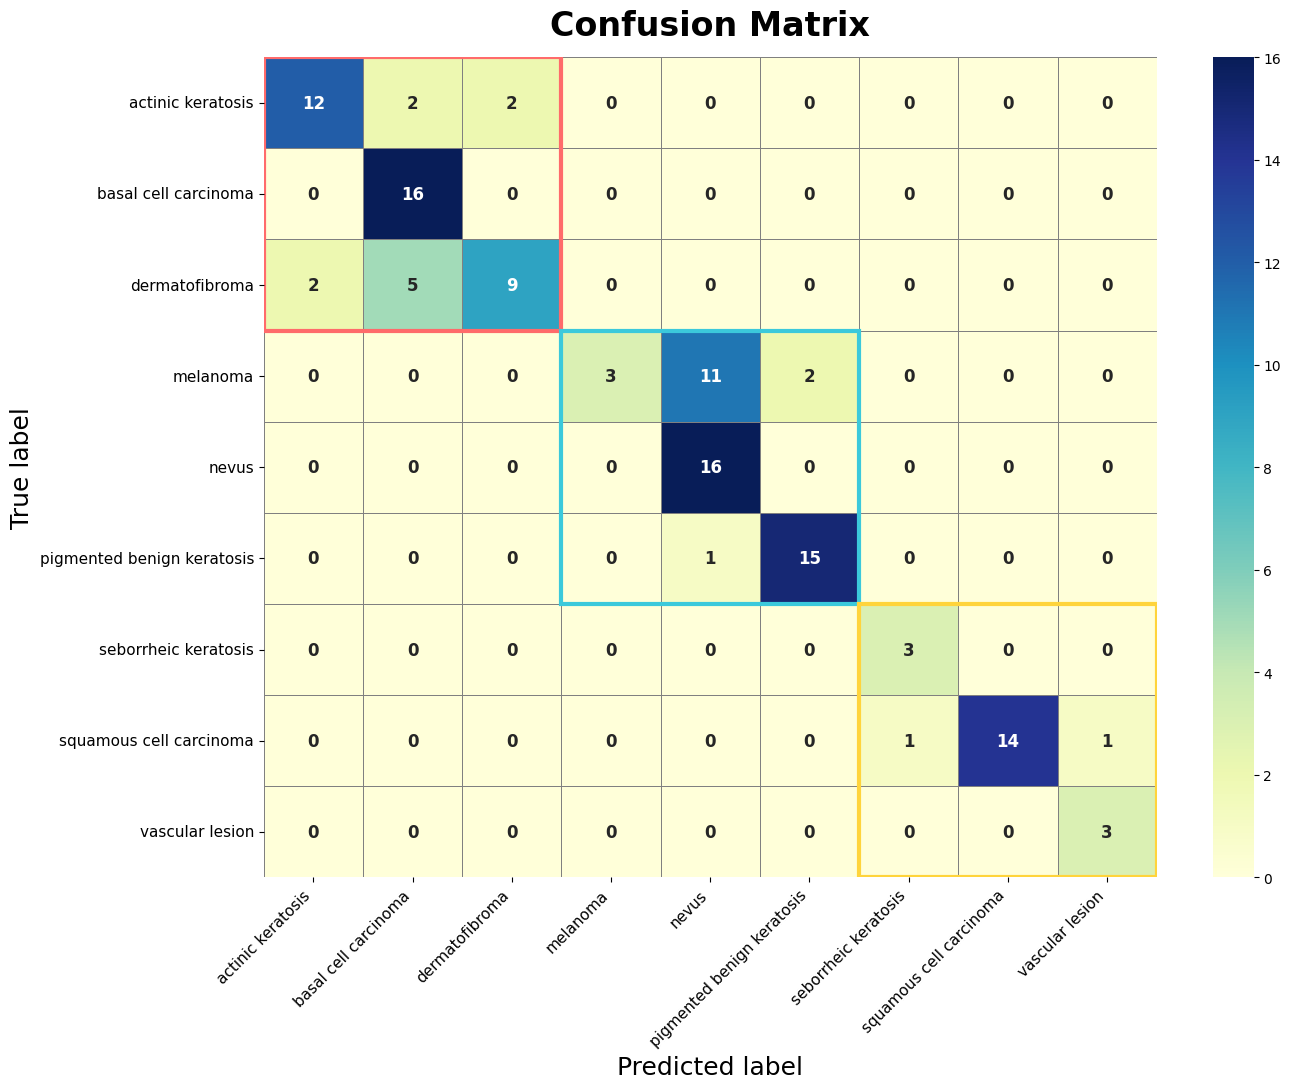

In [20]:
# CONFUSION MATRIX

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

# Build task-wise class index sets
task_class_indices = []
for task in TASKS:
    idxs = [class_to_new_idx[c] for c in task]
    task_class_indices.append(idxs)

# map each class index -> its task id
class_to_task_id = {}
for t_id, idxs in enumerate(task_class_indices):
    for idx in idxs:
        class_to_task_id[idx] = t_id

# Full test loader
overall_test_loader = DataLoader(
    full_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

model.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for images, labels in overall_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)   # shape: [B, 9]

        batch_preds = []

        for i in range(len(labels)):
            true_label = labels[i].item()

            task_id = class_to_task_id[true_label]
            allowed_classes = task_class_indices[task_id]

            allowed_logits = outputs[i, allowed_classes]
            pred_local = torch.argmax(allowed_logits).item()
            pred_global = allowed_classes[pred_local]

            batch_preds.append(pred_global)

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(batch_preds)

all_true = np.array(all_true)
all_pred = np.array(all_pred)

# Confusion matrix
cm = confusion_matrix(all_true, all_pred, labels=list(range(len(CLASS_ORDER))))

class_labels = [new_idx_to_class[i] for i in range(len(CLASS_ORDER))]

# Plot
plt.figure(figsize=(14, 11))
ax = sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    cbar=True,
    xticklabels=class_labels,
    yticklabels=class_labels,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title("Confusion Matrix", fontsize=24, weight='bold', pad=16)
plt.xlabel("Predicted label", fontsize=18)
plt.ylabel("True label", fontsize=18)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(rotation=0, fontsize=11)

task_colors = ['#ff6b6b', '#3bc9db', '#ffd43b']

for task_id, color in enumerate(task_colors):
    start = task_id * 3
    end = start + 3

    rect = plt.Rectangle(
        (start, start),
        3,
        3,
        fill=False,
        edgecolor=color,
        linewidth=3.0
    )
    ax.add_patch(rect)

plt.tight_layout()
plt.show()

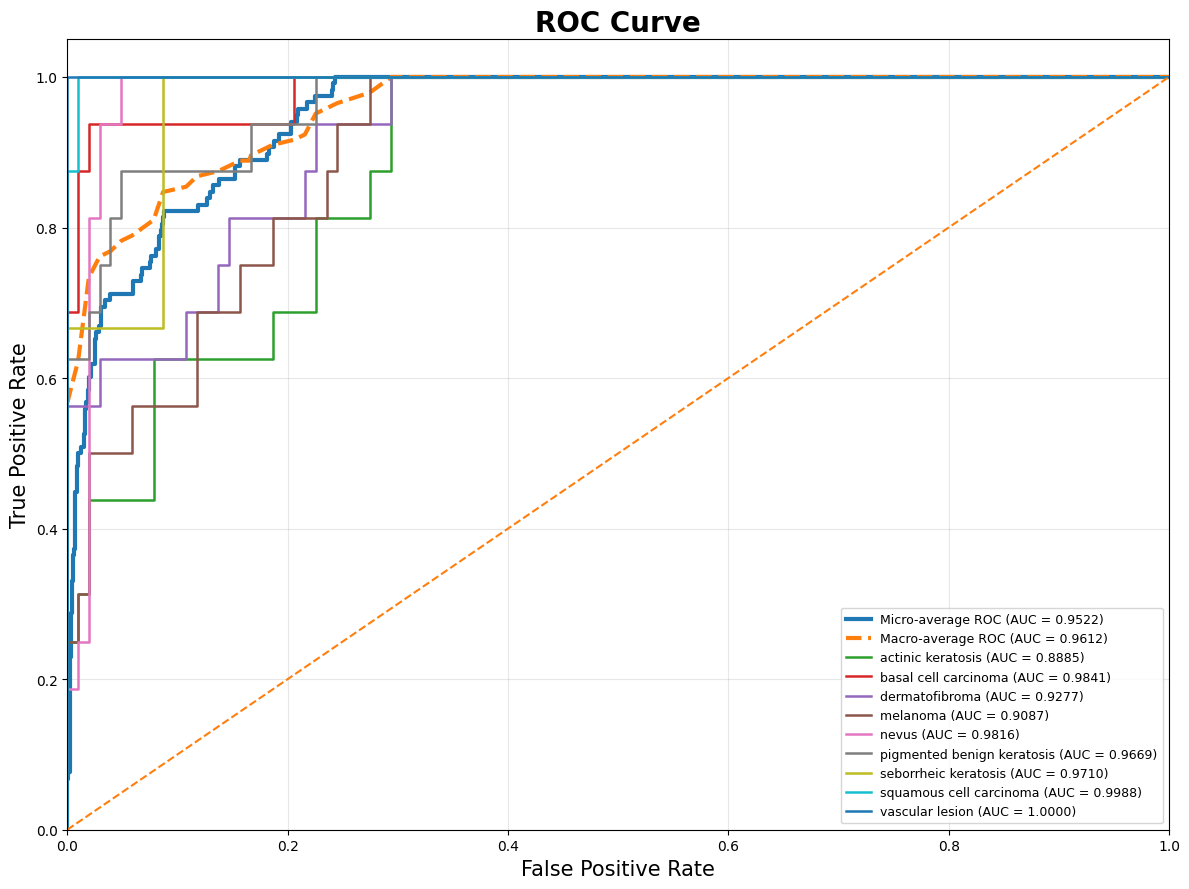

In [21]:
# ROC CURVE

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from torch.utils.data import DataLoader

task_class_indices = []
for task in TASKS:
    idxs = [class_to_new_idx[c] for c in task]
    task_class_indices.append(idxs)

class_to_task_id = {}
for t_id, idxs in enumerate(task_class_indices):
    for idx in idxs:
        class_to_task_id[idx] = t_id

overall_test_loader = DataLoader(
    full_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

model.eval()

all_true = []
all_scores = []

num_classes = len(CLASS_ORDER)

with torch.no_grad():
    for images, labels in overall_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        for i in range(len(labels)):
            true_label = labels[i].item()
            task_id = class_to_task_id[true_label]
            allowed_classes = task_class_indices[task_id]

            masked_scores = np.full(num_classes, -1e9, dtype=np.float32)

            logits = outputs[i].detach().cpu().numpy()
            masked_scores[allowed_classes] = logits[allowed_classes]

            all_true.append(true_label)
            all_scores.append(masked_scores)

all_true = np.array(all_true)
all_scores = np.array(all_scores)

y_true_bin = label_binarize(all_true, classes=np.arange(num_classes))

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    if len(np.unique(y_true_bin[:, i])) < 2:
        continue

    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), all_scores.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

valid_class_indices = [i for i in range(num_classes) if i in fpr]

all_fpr = np.unique(np.concatenate([fpr[i] for i in valid_class_indices]))
mean_tpr = np.zeros_like(all_fpr)

for i in valid_class_indices:
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= len(valid_class_indices)

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

plt.figure(figsize=(12, 9))

plt.plot(
    fpr["micro"], tpr["micro"],
    linewidth=3,
    label=f"Micro-average ROC (AUC = {roc_auc['micro']:.4f})"
)

plt.plot(
    fpr["macro"], tpr["macro"],
    linewidth=3,
    linestyle='--',
    label=f"Macro-average ROC (AUC = {roc_auc['macro']:.4f})"
)

for i in valid_class_indices:
    plt.plot(
        fpr[i], tpr[i],
        linewidth=1.8,
        label=f"{new_idx_to_class[i]} (AUC = {roc_auc[i]:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle='--', linewidth=1.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=15)
plt.ylabel("True Positive Rate", fontsize=15)
plt.title("ROC Curve", fontsize=20, weight='bold')
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

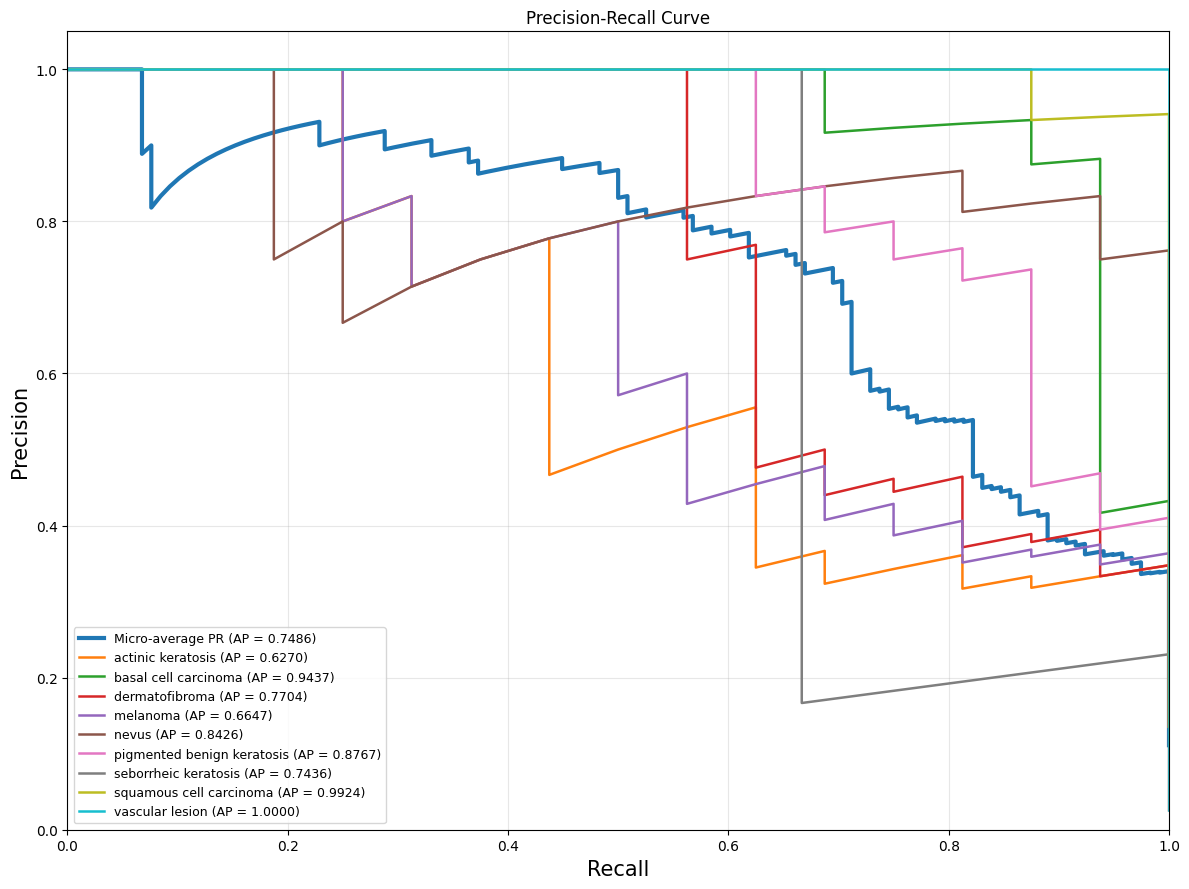

In [22]:
# PRECISION-RECALL CURVE

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score
from torch.utils.data import DataLoader


task_class_indices = []
for task in TASKS:
    idxs = [class_to_new_idx[c] for c in task]
    task_class_indices.append(idxs)

class_to_task_id = {}
for t_id, idxs in enumerate(task_class_indices):
    for idx in idxs:
        class_to_task_id[idx] = t_id

overall_test_loader = DataLoader(
    full_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

model.eval()

all_true = []
all_scores = []

num_classes = len(CLASS_ORDER)

with torch.no_grad():
    for images, labels in overall_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)  # [B, 9]

        for i in range(len(labels)):
            true_label = labels[i].item()
            task_id = class_to_task_id[true_label]
            allowed_classes = task_class_indices[task_id]

            masked_scores = np.full(num_classes, -1e9, dtype=np.float32)

            logits = outputs[i].detach().cpu().numpy()
            masked_scores[allowed_classes] = logits[allowed_classes]

            all_true.append(true_label)
            all_scores.append(masked_scores)

all_true = np.array(all_true)
all_scores = np.array(all_scores)

y_true_bin = label_binarize(all_true, classes=np.arange(num_classes))

precision = {}
recall = {}
avg_precision = {}

for i in range(num_classes):
    if len(np.unique(y_true_bin[:, i])) < 2:
        continue

    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], all_scores[:, i])
    avg_precision[i] = average_precision_score(y_true_bin[:, i], all_scores[:, i])

precision["micro"], recall["micro"], _ = precision_recall_curve(
    y_true_bin.ravel(), all_scores.ravel()
)
avg_precision["micro"] = average_precision_score(
    y_true_bin, all_scores, average="micro"
)

valid_class_indices = [i for i in range(num_classes) if i in precision]
macro_ap = np.mean([avg_precision[i] for i in valid_class_indices])

plt.figure(figsize=(12, 9))

plt.plot(
    recall["micro"], precision["micro"],
    linewidth=3,
    label=f"Micro-average PR (AP = {avg_precision['micro']:.4f})"
)

for i in valid_class_indices:
    plt.plot(
        recall[i], precision[i],
        linewidth=1.8,
        label=f"{new_idx_to_class[i]} (AP = {avg_precision[i]:.4f})"
    )

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall", fontsize=15)
plt.ylabel("Precision", fontsize=15)
plt.title(f"Precision-Recall Curve")
plt.legend(loc="lower left", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# SAVE MODEL TO DESIRED PATH

import os
import torch

SAVE_PATH = "/content/drive/MyDrive/8th-project/saved_models/derpp_skin_cancer_convnext18_new.pth"

# Create folder if it does not exist
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)

torch.save(model.state_dict(), SAVE_PATH)

print(f"Model saved successfully at: {SAVE_PATH}")

Model saved successfully at: /content/drive/MyDrive/8th-project/saved_models/derpp_skin_cancer_convnext18_new.pth


In [24]:
# PRINT ONLY OVERALL TASK-AWARE CLASSIFICATION REPORT

from sklearn.metrics import classification_report
import numpy as np

print("Classification Report:\n")

print(classification_report(
    np.array(task_aware_results["all_true"]),
    np.array(task_aware_results["all_pred"]),
    labels=list(range(len(CLASS_ORDER))),
    target_names=CLASS_ORDER,
    zero_division=0
))

Classification Report:

                            precision    recall  f1-score   support

         actinic keratosis       0.86      0.75      0.80        16
      basal cell carcinoma       0.70      1.00      0.82        16
            dermatofibroma       0.82      0.56      0.67        16
                  melanoma       1.00      0.19      0.32        16
                     nevus       0.57      1.00      0.73        16
pigmented benign keratosis       0.88      0.94      0.91        16
      seborrheic keratosis       0.75      1.00      0.86         3
   squamous cell carcinoma       1.00      0.88      0.93        16
           vascular lesion       0.75      1.00      0.86         3

                  accuracy                           0.77       118
                 macro avg       0.81      0.81      0.77       118
              weighted avg       0.83      0.77      0.74       118

